# Week 9 — Homework 5: Central Limit Theorem and Product Returns
### Central Limit Theorem: Planning for Product Returns
---

DATA-605, Computational Mathematics, Fall 2026

Supervised by: **Professor Jose Jorge Pagan**


Submitted by: **Mehreen Ali Gillani**

## Abstract

This assignment applies the Central Limit Theorem (CLT) to a real-world retail scenario involving product returns. Using a binomial distribution model for 300 independent orders with a 12% return rate, we calculate the expected returns and standard deviation. We then simulate 5,000 cohorts across three sample sizes (n=10, 50 and 300) to visually demonstrate the CLT, showing how the standardized binomial counts converge toward a standard normal distribution as n increases. Finally, we use a continuity-corrected normal approximation and the exact binomial probability to estimate the risk of exceeding a processing capacity of 45 returns. The results show that the approximation is highly accurate but indicates the retailer's capacity fails to meet a 2% overflow risk target, proving the CLT's practical utility in business risk assessment.

## Introduction

In operations management, understanding the variability of product returns is critical for capacity planning. This assignment investigates the return behavior of an online retailer during a promotion of 300 orders, where each order has an independent 12% probability of being returned. Because the number of returns follows a discrete binomial distribution, calculating exact probabilities for large samples can be computationally heavy. However, the Central Limit Theorem (CLT) states that for a sufficiently large sample size, the distribution of the standardized sum of independent random variables approximates a standard normal distribution. This assignment aims to demonstrate this theorem visually through simulation, and practically by using the normal approximation—complete with a continuity correction—to estimate the probability of the retailer's return processing capacity being exceeded.

### Part A — computes E[Sn] and SD(Sn) for n=300, p=0.12.
  

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

# ----------------------------------------------------------------------
# Global setup
# ----------------------------------------------------------------------
rng = np.random.default_rng(605)   # fixed seed for reproducibility


In [14]:
# ----------------------------------------------------------------------
# Part A: Expected Returns
# ----------------------------------------------------------------------                           

print("=" * 70)
print("PART A — EXPECTED RETURNS (n = 300, p = 0.12)")
print("=" * 70)

p = 0.12 # probability of a return
n_campaign = 300
mean_returns = n_campaign * p
sd_returns = np.sqrt(n_campaign * p * (1 - p))

print(f"E[S_{n_campaign}]      = n*p           = {mean_returns:.4f}")
print(f"SD(S_{n_campaign})     = sqrt(n*p*(1-p)) = {sd_returns:.4f}")

print("Interpretation: On average the retailer should expect about "
      f"{mean_returns:.0f} returns per campaign.")
# display the typical spread around that average      
print(f"The typical spread around that average is about {sd_returns:.2f} returns.")
print(f"So return counts commonly fall roughly between "
      f"{mean_returns - sd_returns:.1f} and {mean_returns + sd_returns:.1f}.")
print(f"Capacity of 45 is {((45 - mean_returns) / sd_returns):.2f} standard "
      "deviations above the mean.")
print()

PART A — EXPECTED RETURNS (n = 300, p = 0.12)
E[S_300]      = n*p           = 36.0000
SD(S_300)     = sqrt(n*p*(1-p)) = 5.6285
Interpretation: On average the retailer should expect about 36 returns per campaign.
The typical spread around that average is about 5.63 returns.
So return counts commonly fall roughly between 30.4 and 41.6.
Capacity of 45 is 1.60 standard deviations above the mean.



**Results for Retailer**

**Average Workload:** On a typical 300-order promotion, the retailer should staff and prepare for roughly 36 returns. This is the baseline expectation for daily operations.

**Typical Fluctuations:** Most of the time (about 68% of the time), the number of returns will fluctuate by about 5.6 returns up or down from that average.

**Normal Range:** This means in a typical week, they can expect anywhere from 30 to 42 returns.

**Capacity Context:** Their current capacity is 45. Since 45 is about 1.6 standard deviations above the average, hitting this limit is uncommon but not impossible. It gives them a decent "cushion" for busy weeks, though they should be prepared for occasional spikes that push them near their limit.

### Part B — simulates 5,000 cohorts for n=10, 50, 300, standardizes the counts, and plots histograms overlaid with the N(0,1) density.


PART B — CLT DEMONSTRATION (5,000 simulated cohorts per n)


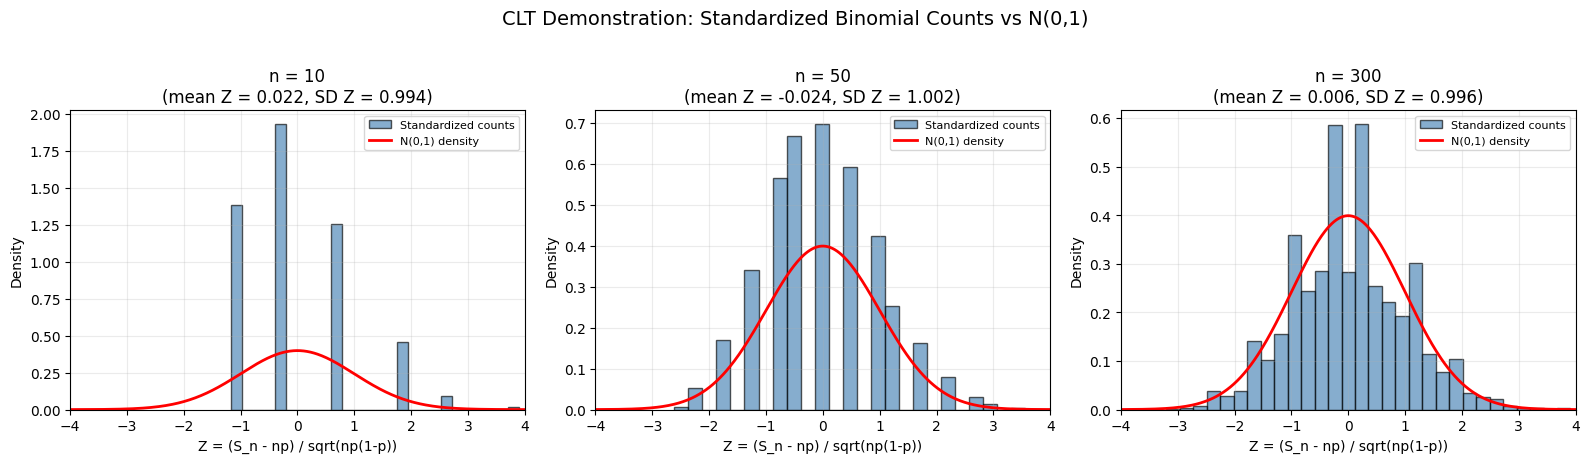

In [15]:
# ----------------------------------------------------------------------
# PART B — Demonstrate the CLT
# ----------------------------------------------------------------------
print("=" * 70)
print("PART B — CLT DEMONSTRATION (5,000 simulated cohorts per n)")
print("=" * 70)

cohort_sizes = [10, 50, 300]
n_sims = 5000

# We will make a 1x3 figure of histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Grid for the standard normal density overlay
z_grid = np.linspace(-4, 4, 400)
normal_density = norm.pdf(z_grid)

for ax, n in zip(axes, cohort_sizes):
    # Simulate 5,000 independent cohort return counts
    counts = rng.binomial(n, p, size=n_sims)

    # Standardize: Z = (Sn - n*p) / sqrt(n*p*(1-p))
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))
    z = (counts - mu) / sigma

    # Histogram of standardized counts (density scale so it matches the pdf)
    ax.hist(z, bins=30, density=True, alpha=0.65,
            color="steelblue", edgecolor="black", label="Standardized counts")

    # Overlay standard normal density
    ax.plot(z_grid, normal_density, "r-", linewidth=2, label="N(0,1) density")

    ax.set_title(f"n = {n}\n(mean Z = {z.mean():.3f}, SD Z = {z.std():.3f})")
    ax.set_xlabel("Z = (S_n - np) / sqrt(np(1-p))")
    ax.set_ylabel("Density")
    ax.set_xlim(-4, 4)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle("CLT Demonstration: Standardized Binomial Counts vs N(0,1)",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("clt_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation of the CLT Demonstration**

**n=10** *(Left Panel):*

The standardized distribution is highly discrete, showing distinct "spikes" and gaps rather than a smooth curve.
It is noticeably **asymmetric (skewed)**.
The normal overlay (red line) is a poor fit, failing to capture the discrete nature and skewness of the data. The central spike reaches a density near 2.0, while the normal curve peaks at less than 0.5.

**n=50** *(Middle Panel):*

The distribution becomes much more **symmetric and bell-shaped**, though the discrete steps are still visible.
The normal overlay is a reasonable approximation, but it is still imperfect. For example, the normal curve slightly underestimates the height of the central bins (peaking around 0.4 while the bars reach near 0.8).

**n=300** *(Right Panel):*

The standardized counts closely follow a **smooth, bell-shaped curve**.
The normal overlay is an excellent fit, closely tracing the tops of the histogram bins. The empirical mean **(0.027)** and standard deviation (0.987) are also very close to the theoretical N(0,1) values of 0 and 1.

**Conclusion:** The normal approximation becomes increasingly reasonable and accurate as the sample size (n) increases, exactly as the Central Limit Theorem predicts.

### Part C — estimates P(S300 > 45) via the continuity-corrected normal approximation and the exact binomial, compares them, and checks the 2% overflow-risk target.

In [16]:
# ----------------------------------------------------------------------
# PART C — Risk of exceeding capacity (n = 300, capacity = 45)
# ----------------------------------------------------------------------
print("=" * 70)
print("PART C — RISK OF EXCEEDING CAPACITY (n = 300, capacity = 45)")
print("=" * 70)

n = 300
capacity = 45
# Exceeding capacity means 46 or more returns -> continuity boundary 45.5
boundary = capacity + 0.5

mu = n * p
sigma = np.sqrt(n * p * (1 - p))

# Continuity-corrected normal approximation
z_cc = (boundary - mu) / sigma
p_approx = norm.sf(z_cc)          # 1 - Phi(z)

# Exact binomial probability P(S > 45)
p_exact = binom.sf(capacity, n, p)   # binom.sf(45, 300, 0.12)

# Absolute error
abs_error = abs(p_approx - p_exact)

print(f"Mean np            = {mu:.4f}")
print(f"SD sqrt(np(1-p))   = {sigma:.4f}")
print(f"Continuity boundary= {boundary}")
print(f"z (continuity corr)= (45.5 - {mu:.2f}) / {sigma:.4f} = {z_cc:.4f}")
print()
print(f"Approximate P(S300 > 45) = 1 - Phi(z) = {p_approx:.6f}")
print(f"Exact binomial P(S300 > 45)          = {p_exact:.6f}")
print(f"Absolute error |approx - exact|      = {abs_error:.6f}")
print()
print(f"Relative error                       = {abs_error / p_exact * 100:.3f}%")
print()

# Capacity check against the 2% target
target = 0.02
print("Capacity assessment (target: overflow risk <= 2%):")
print(f"  Exact overflow risk      = {p_exact * 100:.3f}%")
print(f"  Approx overflow risk     = {p_approx * 100:.3f}%")
print(f"  Target                   = {target * 100:.1f}%")
if p_exact <= target:
    print("  -> Exact risk is BELOW 2%: capacity 45 MEETS the target.")
else:
    print("  -> Exact risk is ABOVE 2%: capacity 45 does NOT meet the target.")
if p_approx <= target:
    print("  -> Approx risk is BELOW 2%: approximation also says capacity 45 MEETS the target.")
else:
    print("  -> Approx risk is ABOVE 2%: approximation also says capacity 45 does NOT meet the target.")

if (p_exact <= target) == (p_approx <= target):
    print("  -> Both methods reach the SAME conclusion.")
else:
    print("  -> WARNING: the two methods reach DIFFERENT conclusions.")


PART C — RISK OF EXCEEDING CAPACITY (n = 300, capacity = 45)
Mean np            = 36.0000
SD sqrt(np(1-p))   = 5.6285
Continuity boundary= 45.5
z (continuity corr)= (45.5 - 36.00) / 5.6285 = 1.6878

Approximate P(S300 > 45) = 1 - Phi(z) = 0.045721
Exact binomial P(S300 > 45)          = 0.049309
Absolute error |approx - exact|      = 0.003588

Relative error                       = 7.277%

Capacity assessment (target: overflow risk <= 2%):
  Exact overflow risk      = 4.931%
  Approx overflow risk     = 4.572%
  Target                   = 2.0%
  -> Exact risk is ABOVE 2%: capacity 45 does NOT meet the target.
  -> Approx risk is ABOVE 2%: approximation also says capacity 45 does NOT meet the target.
  -> Both methods reach the SAME conclusion.


**Approximation vs. Exact Probability:**

The continuity-corrected normal approximation estimates the overflow risk at 4.572%.
The exact binomial probability calculates the overflow risk at 4.931%.
The absolute difference between the two is very small (0.0036, or about a 0.36 percentage point difference), indicating that the normal approximation is highly accurate for this sample size (n=300)

**Capacity Target Assessment:**

The retailer's target is an overflow risk of no more than 2%.
Both the exact method (~4.93%) and the approximation (~4.57%) are well above the 2% target.
Therefore, the current capacity of 45 returns does not meet the retailer's risk tolerance. The retailer would need to increase their return-processing capacity to reduce the risk to 2% or lower.

**Takeaway**  Despite the small numerical difference (a 7.28% relative error), the approximate and exact results lead to the exact same practical conclusion: capacity 45 is insufficient for the 2% target. This demonstrates that the CLT-based normal approximation is a reliable tool for this type of business risk assessment.

## Conclusion

This assignment successfully demonstrated the Central Limit Theorem in both theoretical and practical contexts. The simulations confirmed that while the normal approximation is poor for small cohorts (n=10), it becomes exceptionally accurate as the sample size grows to n=300, where the standardized binomial counts closely mirror the standard normal curve. In the practical risk assessment, the continuity-corrected normal approximation estimated a 4.57% chance of exceeding the 45-return capacity, which was within a mere 0.36 percentage points (absolute error) of the exact binomial probability of 4.93%. Because both methods yielded a risk well above the retailer's 2% target, we conclude that a capacity of 45 returns is insufficient. Ultimately, the assignment highlights how the CLT provides a reliable, accurate, and computationally simple tool for making data-driven business decisions.

------------